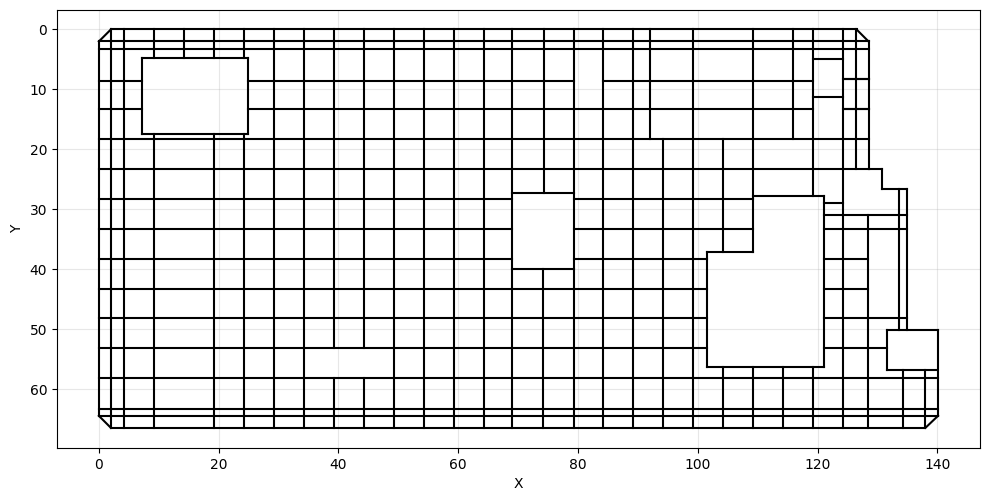

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


class SegmentPlotter:
    """
    Plot line segments defined by (X1,Y1) -> (X2,Y2) from an Excel file.
    """

    def __init__(self, excel_path: str):
        self.excel_path = excel_path
        self.segments = []

    def load_from_excel(self) -> None:
        # Read Excel file
        df = pd.read_excel(self.excel_path)

        # Keep only the needed columns
        df = df[["X1", "Y1", "X2", "Y2"]]

        # Replace empty cells with zero
        df = df.fillna(0)

        # Store segments
        for _, row in df.iterrows():
            x1 = float(row["X1"])
            y1 = float(row["Y1"])
            x2 = float(row["X2"])
            y2 = float(row["Y2"])

            self.segments.append((x1, y1, x2, y2))

    def plot(self) -> None:
        if len(self.segments) == 0:
            raise ValueError("No segments loaded. Did you call load_from_excel()?")

        plt.figure(figsize=(10, 6))

        # Plot all segments with the same color
        for (x1, y1, x2, y2) in self.segments:
            plt.plot(
                [x1, x2],
                [y1, y2],
                linewidth=1.5,
                color="black"
            )

        # Equal scale + inverted Y axis (Y grows downward)
        plt.gca().set_aspect("equal", adjustable="box")
        plt.gca().invert_yaxis()

        plt.grid(True, alpha=0.3)
        plt.xlabel("X")
        plt.ylabel("Y")
        # plt.title("Line Segments from Excel (Y inverted)")
        plt.tight_layout()
        plt.show()


if __name__ == "__main__":

    excel_file = r"coordenadas_para_grafico.xlsx"

    plotter = SegmentPlotter(excel_file)
    plotter.load_from_excel()
    plotter.plot()
